# DROUGHTS

## INTRODUCCIÓN Y OBJETIVOS

Objetivo del estudio

El objetivo de este análisis es estudiar la relación entre los episodios de calor extremo y los periodos de déficit de precipitaciones con la disponibilidad de recursos hídricos en Cataluña.

Para ello, se utilizarán datos meteorológicos de Meteocat (XEMA) y datos hidrológicos de la Agència Catalana de l'Aigua (ACA), incluyendo información sobre las reservas de los embalses y los estados oficiales de sequía.

Se pretende:
- Identificar episodios de temperaturas extremas y déficit de precipitaciones.
- Analizar la evolución temporal de las reservas de agua.
- Estudiar la relación entre las condiciones meteorológicas y la disponibilidad de agua.
- Comparar los indicadores meteorológicos e hidrológicos con los estados oficiales de sequía.
- Identificar posibles retardos temporales entre la falta de precipitaciones y sus efectos sobre los recursos hídricos.

## IMPORTACIÓN LIBRERÍAS

In [1]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid")


## CARGAR LOS DATOS DE LA XEMA

In [2]:
# XEMA - Meteorological daily data

path_xema = r"C:\Users\nmayo\OneDrive\Escritorio\Máster - UB\Análisis de datos masivos\Datasets - Agua\Dades_meteorològiques_diàries_de_la_XEMA_20261116.csv"
df_xema = pd.read_csv(path_xema, low_memory=False)

print("Dimensions:", df_xema.shape)

display(df_xema.head())

Dimensions: (33475032, 10)


,ID,CODI_ESTACIO,NOM_ESTACIO,DATA_LECTURA,CODI_VARIABLE,NOM_VARIABLE,VALOR,UNITAT,HORA _TU,Estat
0,VK1000098801,VK,Raimat,01/09/1988,1.00,Temperatura mitjana diària,"23,3",°C,NaN,Representatiu
1,VK1002098801,VK,Raimat,01/09/1988,1.00,Temperatura mínima diària + hora,"18,3",°C,0:00,Representatiu
2,VK1100098801,VK,Raimat,01/09/1988,1.10,Humitat relativa mitjana diària,58,%,NaN,Representatiu
3,VK1300098801,VK,Raimat,01/09/1988,1.30,Precipitació acumulada diària,"0,6",mm,NaN,Representatiu
4,VK1301098801,VK,Raimat,01/09/1988,1.30,Precipitació acumulada diària (8-8 h),"0,6",mm,NaN,Representatiu


## CARGA DATOS DE LOS EMBALSES DE LA ACA

In [3]:
# ACA - Water quantity in reservoirs

url_aca = "https://analisi.transparenciacatalunya.cat/api/v3/views/gn9e-3qhr/query.json"

def download_socrata(url, limit=1000000):

    frames = []
    offset = 0

    while True:

        params = {
            "$limit": limit,
            "$offset": offset
        }

        response = requests.get(url, params=params)
        response.raise_for_status()

        batch = response.json()

        if len(batch) == 0:
            break

        frames.append(pd.DataFrame(batch))
        offset += len(batch)

        print(f"Downloaded {offset} records")

        if len(batch) < limit:
            break

    return pd.concat(frames, ignore_index=True)


df_aca = download_socrata(url_aca)

print("ACA reservoirs loaded successfully")
print("Dimensions:", df_aca.shape)

display(df_aca.head())

Downloaded 88354 records
ACA reservoirs loaded successfully
Dimensions: (88354, 9)


,:id,:version,:created_at,:updated_at,dia,estaci,nivell_absolut,percentatge_volum_embassat,volum_embassat
0,row-kefq~575y.4dty,rv-rdjg.vtvg-8jwv,2026-10-22T10:00:11.267Z,2026-11-05T11:00:09.027Z,2026-10-22T00:00:00.000,Embassament de la Llosa del Cavall (Navès),801.42,83.9,60.01
1,row-jvef-nqxr_3ujb,rv-uy3d_6v7c~c75v,2026-10-22T10:00:11.267Z,2026-11-05T11:00:09.027Z,2026-10-22T00:00:00.000,Embassament de Siurana (Cornudella de Montsant),480.61,71.5,8.59
2,row-mepu~3j9s~yxue,rv-9khj~qiyx_5jcx,2026-10-23T10:00:11.489Z,2026-11-05T11:00:09.027Z,2026-10-23T00:00:00.000,Embassament de la Llosa del Cavall (Navès),801.44,83.9,60.06
3,row-qqqa.yne6~ka3e,rv-rxnf~xvxy-apzp,2026-10-26T11:00:11.605Z,2026-11-05T11:00:09.027Z,2026-10-26T00:00:00.000,Embassament de la Llosa del Cavall (Navès),801.41,83.8,59.99
4,row-ssbv~i4vi_q9rd,rv-iw2k_2m4s-za28,2026-10-26T11:00:11.605Z,2026-11-05T11:00:09.027Z,2026-10-26T00:00:00.000,Embassament de Siurana (Cornudella de Montsant),480.58,71.4,8.57


## DESCARGAR DATOS DE SEQUÍA

In [4]:
# ACA - Official drought status

url_sequera = "https://analisi.transparenciacatalunya.cat/api/v3/views/i5n8-43cw/query.json"
df_sequera = download_socrata(url_sequera)

print("Dimensions:", df_sequera.shape)

display(df_sequera.head())

Downloaded 8677 records
Dimensions: (8677, 13)


,:id,:version,:created_at,:updated_at,data_canvi_estat_sequera,codi_unitat_explotaci,unitat_explotaci,codi_estat_sequera_hidrol,estat_sequera_hidrol_gic,codi_estat_sequera_pluviom,estat_sequera_pluviom_tric,codi_municipi,municipi
0,row-siqu~mz5e~hh2f,rv-e84a-ywg9~7p97,2025-05-17T08:54:07.369Z,2025-05-17T08:54:07.369Z,2025-05-16T00:00:00.000,03,Aqüífer Fluvià - Muga,00004,NORMALITAT,00001,NORMALITAT,170010,Agullana
1,row-t4ph-fgsd-kbsv,rv-eiav_8cu9.i54v,2025-05-17T08:54:07.369Z,2025-05-17T08:54:07.369Z,2025-05-16T00:00:00.000,03,Aqüífer Fluvià - Muga,00004,NORMALITAT,00001,NORMALITAT,170118,"Armentera, l'"
2,row-6szz.h62x~xu7q,rv-fjk4-h3ir-rtdk,2025-05-17T08:54:07.369Z,2025-05-17T08:54:07.369Z,2025-05-16T00:00:00.000,03,Aqüífer Fluvià - Muga,00004,NORMALITAT,00001,NORMALITAT,170427,Capmany
3,row-zsrx-69ui-8wzf,rv-bsk2.cien-4j8h,2025-05-17T08:54:07.369Z,2025-05-17T08:54:07.369Z,2025-05-16T00:00:00.000,03,Aqüífer Fluvià - Muga,00004,NORMALITAT,00001,NORMALITAT,170643,Espolla
4,row-sj7b-amak-5hxn,rv-xznj~5y2f~xf53,2025-05-17T08:54:07.369Z,2025-05-17T08:54:07.369Z,2025-05-16T00:00:00.000,03,Aqüífer Fluvià - Muga,00004,NORMALITAT,00001,NORMALITAT,170773,Garriguella


## EXPLORACIÓN DE LOS DATASETS

### DIMENSIONES Y COLUMNAS

In [5]:
datasets = {
    "XEMA": df_xema,
    "ACA reservoirs": df_aca,
    "ACA drought": df_sequera
}

for name, df in datasets.items():

    print("\n" + "="*60)
    print(name)
    print("="*60)

    print("Dimensions:", df.shape)
    print("Columns:", df.columns.tolist())


XEMA
Dimensions: (33475032, 10)
Columns: ['ID', 'CODI_ESTACIO', 'NOM_ESTACIO', 'DATA_LECTURA', 'CODI_VARIABLE', 'NOM_VARIABLE', 'VALOR', 'UNITAT', 'HORA _TU', 'Estat']

ACA reservoirs
Dimensions: (88354, 9)
Columns: [':id', ':version', ':created_at', ':updated_at', 'dia', 'estaci', 'nivell_absolut', 'percentatge_volum_embassat', 'volum_embassat']

ACA drought
Dimensions: (8677, 13)
Columns: [':id', ':version', ':created_at', ':updated_at', 'data_canvi_estat_sequera', 'codi_unitat_explotaci', 'unitat_explotaci', 'codi_estat_sequera_hidrol', 'estat_sequera_hidrol_gic', 'codi_estat_sequera_pluviom', 'estat_sequera_pluviom_tric', 'codi_municipi', 'municipi']


### TIPOS DE VARIABLES

In [6]:
for name, df in datasets.items():

    print("\n" + "="*60)
    print(name)
    print("="*60)

    display(pd.DataFrame({
        "Column": df.columns,
        "Data type": df.dtypes.astype(str).values
    }))


XEMA


,Column,Data type
0,ID,str
1,CODI_ESTACIO,str
2,NOM_ESTACIO,str
3,DATA_LECTURA,str
4,CODI_VARIABLE,float64
5,NOM_VARIABLE,str
6,VALOR,str
7,UNITAT,str
8,HORA _TU,str
9,Estat,str



ACA reservoirs


,Column,Data type
0,:id,str
1,:version,str
2,:created_at,str
3,:updated_at,str
4,dia,str
5,estaci,str
6,nivell_absolut,str
7,percentatge_volum_embassat,str
8,volum_embassat,str



ACA drought


,Column,Data type
0,:id,str
1,:version,str
2,:created_at,str
3,:updated_at,str
4,data_canvi_estat_sequera,str
5,codi_unitat_explotaci,str
6,unitat_explotaci,str
7,codi_estat_sequera_hidrol,str
8,estat_sequera_hidrol_gic,str
9,codi_estat_sequera_pluviom,str


### PRIMERAS FILAS

In [7]:
for name, df in datasets.items():

    print("\n" + "="*60)
    print(name)
    print("="*60)

    display(df.head())


XEMA


,ID,CODI_ESTACIO,NOM_ESTACIO,DATA_LECTURA,CODI_VARIABLE,NOM_VARIABLE,VALOR,UNITAT,HORA _TU,Estat
0,VK1000098801,VK,Raimat,01/09/1988,1.00,Temperatura mitjana diària,"23,3",°C,NaN,Representatiu
1,VK1002098801,VK,Raimat,01/09/1988,1.00,Temperatura mínima diària + hora,"18,3",°C,0:00,Representatiu
2,VK1100098801,VK,Raimat,01/09/1988,1.10,Humitat relativa mitjana diària,58,%,NaN,Representatiu
3,VK1300098801,VK,Raimat,01/09/1988,1.30,Precipitació acumulada diària,"0,6",mm,NaN,Representatiu
4,VK1301098801,VK,Raimat,01/09/1988,1.30,Precipitació acumulada diària (8-8 h),"0,6",mm,NaN,Representatiu



ACA reservoirs


,:id,:version,:created_at,:updated_at,dia,estaci,nivell_absolut,percentatge_volum_embassat,volum_embassat
0,row-kefq~575y.4dty,rv-rdjg.vtvg-8jwv,2026-10-22T10:00:11.267Z,2026-11-05T11:00:09.027Z,2026-10-22T00:00:00.000,Embassament de la Llosa del Cavall (Navès),801.42,83.9,60.01
1,row-jvef-nqxr_3ujb,rv-uy3d_6v7c~c75v,2026-10-22T10:00:11.267Z,2026-11-05T11:00:09.027Z,2026-10-22T00:00:00.000,Embassament de Siurana (Cornudella de Montsant),480.61,71.5,8.59
2,row-mepu~3j9s~yxue,rv-9khj~qiyx_5jcx,2026-10-23T10:00:11.489Z,2026-11-05T11:00:09.027Z,2026-10-23T00:00:00.000,Embassament de la Llosa del Cavall (Navès),801.44,83.9,60.06
3,row-qqqa.yne6~ka3e,rv-rxnf~xvxy-apzp,2026-10-26T11:00:11.605Z,2026-11-05T11:00:09.027Z,2026-10-26T00:00:00.000,Embassament de la Llosa del Cavall (Navès),801.41,83.8,59.99
4,row-ssbv~i4vi_q9rd,rv-iw2k_2m4s-za28,2026-10-26T11:00:11.605Z,2026-11-05T11:00:09.027Z,2026-10-26T00:00:00.000,Embassament de Siurana (Cornudella de Montsant),480.58,71.4,8.57



ACA drought


,:id,:version,:created_at,:updated_at,data_canvi_estat_sequera,codi_unitat_explotaci,unitat_explotaci,codi_estat_sequera_hidrol,estat_sequera_hidrol_gic,codi_estat_sequera_pluviom,estat_sequera_pluviom_tric,codi_municipi,municipi
0,row-siqu~mz5e~hh2f,rv-e84a-ywg9~7p97,2025-05-17T08:54:07.369Z,2025-05-17T08:54:07.369Z,2025-05-16T00:00:00.000,03,Aqüífer Fluvià - Muga,00004,NORMALITAT,00001,NORMALITAT,170010,Agullana
1,row-t4ph-fgsd-kbsv,rv-eiav_8cu9.i54v,2025-05-17T08:54:07.369Z,2025-05-17T08:54:07.369Z,2025-05-16T00:00:00.000,03,Aqüífer Fluvià - Muga,00004,NORMALITAT,00001,NORMALITAT,170118,"Armentera, l'"
2,row-6szz.h62x~xu7q,rv-fjk4-h3ir-rtdk,2025-05-17T08:54:07.369Z,2025-05-17T08:54:07.369Z,2025-05-16T00:00:00.000,03,Aqüífer Fluvià - Muga,00004,NORMALITAT,00001,NORMALITAT,170427,Capmany
3,row-zsrx-69ui-8wzf,rv-bsk2.cien-4j8h,2025-05-17T08:54:07.369Z,2025-05-17T08:54:07.369Z,2025-05-16T00:00:00.000,03,Aqüífer Fluvià - Muga,00004,NORMALITAT,00001,NORMALITAT,170643,Espolla
4,row-sj7b-amak-5hxn,rv-xznj~5y2f~xf53,2025-05-17T08:54:07.369Z,2025-05-17T08:54:07.369Z,2025-05-16T00:00:00.000,03,Aqüífer Fluvià - Muga,00004,NORMALITAT,00001,NORMALITAT,170773,Garriguella


### VALORES NULOS

In [8]:
for name, df in datasets.items():

    print("\n" + "="*60)
    print(name)
    print("="*60)

    missing = pd.DataFrame({
        "Missing values": df.isnull().sum(),
        "Percentage (%)": df.isnull().mean() * 100
    })

    display(missing)


XEMA


,Missing values,Percentage (%)
ID,0,0.00
CODI_ESTACIO,0,0.00
NOM_ESTACIO,0,0.00
DATA_LECTURA,0,0.00
CODI_VARIABLE,0,0.00
NOM_VARIABLE,0,0.00
VALOR,0,0.00
UNITAT,0,0.00
HORA _TU,17902103,53.48
Estat,10699,0.03



ACA reservoirs


,Missing values,Percentage (%)
:id,0,0.00
:version,0,0.00
:created_at,0,0.00
:updated_at,0,0.00
dia,0,0.00
estaci,0,0.00
nivell_absolut,53,0.06
percentatge_volum_embassat,0,0.00
volum_embassat,0,0.00



ACA drought


,Missing values,Percentage (%)
:id,0,0.00
:version,0,0.00
:created_at,0,0.00
:updated_at,0,0.00
data_canvi_estat_sequera,0,0.00
codi_unitat_explotaci,0,0.00
unitat_explotaci,0,0.00
codi_estat_sequera_hidrol,0,0.00
estat_sequera_hidrol_gic,0,0.00
codi_estat_sequera_pluviom,0,0.00


### DUPLICADOS

In [9]:
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} duplicated rows")

XEMA: 0 duplicated rows
ACA reservoirs: 0 duplicated rows
ACA drought: 0 duplicated rows


## PREPARACIÓN DE LOS DATASETS

### INSPECT METEOROLOGICAL VARIABLES

In [11]:
# Display all available meteorological variables

variables_xema = (
    df_xema["NOM_VARIABLE"]
    .value_counts()
    .reset_index()
)

variables_xema.columns = ["Variable", "Number of records"]

display(variables_xema)

# Check what stations we have
print("Number of meteorological stations:",
      df_xema["CODI_ESTACIO"].nunique())

print("Number of different station names:",
      df_xema["NOM_ESTACIO"].nunique())

,Variable,Number of records
0,Precipitació acumulada diària,1850932
1,Precipitació acumulada diària (8-8 h),1850822
2,Precipitació màxima en 1 h (diària) + hora,1850082
3,Temperatura mitjana diària,1811944
4,Temperatura màxima diària + hora,1809555
...,...,...
72,Velocitat mitjana di�ria del vent 6 m (esc.),39
73,Direcci� mitjana di�ria del vent 6 m (m. 1),39
74,Ratxa m�xima di�ria del vent 6 m + hora,39
75,Direcci� de la ratxa m�x. di�ria de vent 6 m,39


Number of meteorological stations: 246
Number of different station names: 315


### SELECTION OF THE RELEVANT COLUMNS IN EACH DATASET

In [15]:
# XEMA - Meteorological data

xema_selected = df_xema[
    [
        "CODI_ESTACIO",
        "NOM_ESTACIO",
        "DATA_LECTURA",
        "NOM_VARIABLE",
        "VALOR",
        "UNITAT",
        "Estat"
    ]
].copy()


# ACA - Reservoir data

reservoirs_selected = df_aca[
    [
        "dia",
        "estaci",
        "nivell_absolut",
        "percentatge_volum_embassat",
        "volum_embassat"
    ]
].copy()


# ACA - Drought data

drought_selected = df_sequera[
    [
        "data_canvi_estat_sequera",
        "unitat_explotaci",
        "estat_sequera_hidrol_gic",
        "estat_sequera_pluviom_tric",
        "municipi"
    ]
].copy()

# CHANGE OF NAME OF THE COLUMNS (RENAME)
# Rename XEMA columns

xema_selected = xema_selected.rename(columns={
    "CODI_ESTACIO": "station_code",
    "NOM_ESTACIO": "station_name",
    "DATA_LECTURA": "date",
    "NOM_VARIABLE": "variable",
    "VALOR": "value",
    "UNITAT": "unit",
    "Estat": "quality_status"
})


# Rename reservoir columns

reservoirs_selected = reservoirs_selected.rename(columns={
    "dia": "date",
    "estaci": "reservoir",
    "nivell_absolut": "water_level",
    "percentatge_volum_embassat": "water_percentage",
    "volum_embassat": "water_volume_hm3"
})


# Rename drought columns

drought_selected = drought_selected.rename(columns={
    "data_canvi_estat_sequera": "date",
    "unitat_explotaci": "exploitation_unit",
    "estat_sequera_hidrol_gic": "hydrological_drought",
    "estat_sequera_pluviom_tric": "meteorological_drought",
    "municipi": "municipality"
})

### CONVERT DATA TYPES

In [16]:
# Convert XEMA dates and numerical values

xema_selected["date"] = pd.to_datetime(
    xema_selected["date"],
    format="%d/%m/%Y",
    errors="coerce"
)

xema_selected["value"] = pd.to_numeric(
    xema_selected["value"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)


# Convert reservoir dates and numerical values

reservoirs_selected["date"] = pd.to_datetime(
    reservoirs_selected["date"],
    errors="coerce"
)

reservoir_numeric = [
    "water_level",
    "water_percentage",
    "water_volume_hm3"
]

for col in reservoir_numeric:
    reservoirs_selected[col] = pd.to_numeric(
        reservoirs_selected[col],
        errors="coerce"
    )


# Convert drought dates

drought_selected["date"] = pd.to_datetime(
    drought_selected["date"],
    errors="coerce"
)

In [17]:
# Mostrar las variables relacionadas con temperatura, precipitación y humedad

variables_relevantes = variables_xema[
    variables_xema["Variable"].str.contains(
        "temperatura|precipitació|humitat",
        case=False,
        na=False
    )
]

display(variables_relevantes)

,Variable,Number of records
0,Precipitació acumulada diària,1850932
1,Precipitació acumulada diària (8-8 h),1850822
2,Precipitació màxima en 1 h (diària) + hora,1850082
3,Temperatura mitjana diària,1811944
4,Temperatura màxima diària + hora,1809555
5,Temperatura mínima diària + hora,1809297
6,Temperatura mitjana diària clàssica,1807392
8,Humitat relativa mitjana diària,1804786
9,Humitat relativa mínima diària + data,1800567
12,Humitat relativa màxima diària + data,1311876


In [2]:
import pandas as pd

file_path = r"C:\Users\nmayo\OneDrive\Escritorio\Máster - UB\Análisis de datos masivos\Datasets - Agua\Dades_meteorològiques_diàries_de_la_XEMA_20261116.csv"

df = pd.read_csv(file_path, encoding="utf-8")

print("Shape:", df.shape)
print("RAM usage:", round(df.memory_usage(deep=True).sum() / 1024**2, 2), "MB")

display(df.head())

Shape: (33475032, 10)
RAM usage: 5655.45 MB


,ID,CODI_ESTACIO,NOM_ESTACIO,DATA_LECTURA,CODI_VARIABLE,NOM_VARIABLE,VALOR,UNITAT,HORA _TU,Estat
0,VK1000098801,VK,Raimat,01/09/1988,1.000,Temperatura mitjana diària,"23,3",°C,NaN,Representatiu
1,VK1002098801,VK,Raimat,01/09/1988,1.002,Temperatura mínima diària + hora,"18,3",°C,0:00,Representatiu
2,VK1100098801,VK,Raimat,01/09/1988,1.100,Humitat relativa mitjana diària,58,%,NaN,Representatiu
3,VK1300098801,VK,Raimat,01/09/1988,1.300,Precipitació acumulada diària,"0,6",mm,NaN,Representatiu
4,VK1301098801,VK,Raimat,01/09/1988,1.301,Precipitació acumulada diària (8-8 h),"0,6",mm,NaN,Representatiu


In [3]:
import gc

del df
gc.collect()

0

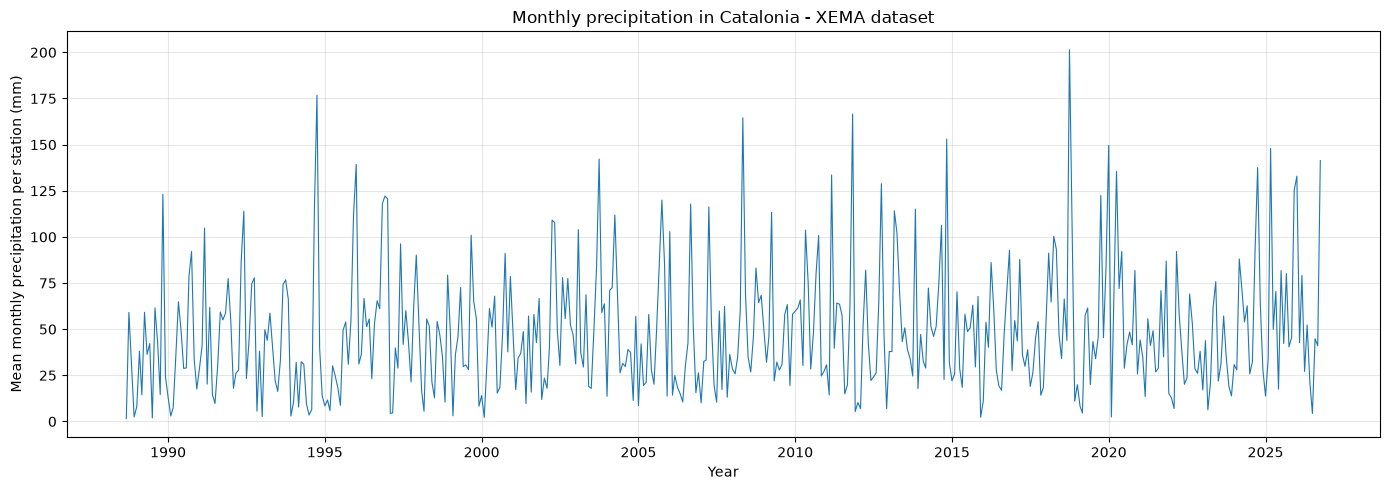

3157

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gc

file_path = r"C:\Users\nmayo\OneDrive\Escritorio\Máster - UB\Análisis de datos masivos\Datasets - Agua\Dades_meteorològiques_diàries_de_la_XEMA_20261116.csv"

# Store partial monthly aggregations
monthly_parts = []

# Read the CSV in chunks
for chunk in pd.read_csv(
    file_path,
    usecols=[
        "CODI_ESTACIO",
        "DATA_LECTURA",
        "NOM_VARIABLE",
        "VALOR"
    ],
    chunksize=300_000
):

    # Keep daily accumulated precipitation
    chunk = chunk[
        chunk["NOM_VARIABLE"] == "Precipitació acumulada diària"
    ].copy()

    if chunk.empty:
        continue

    # Convert values and dates
    chunk["VALOR"] = pd.to_numeric(
        chunk["VALOR"].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

    chunk["DATA_LECTURA"] = pd.to_datetime(
        chunk["DATA_LECTURA"],
        format="%d/%m/%Y",
        errors="coerce"
    )

    chunk = chunk.dropna(
        subset=["VALOR", "DATA_LECTURA"]
    )

    # Create monthly identifier
    chunk["MONTH"] = chunk["DATA_LECTURA"].dt.to_period("M")

    # Monthly precipitation for each station
    grouped = chunk.groupby(
        ["CODI_ESTACIO", "MONTH"]
    )["VALOR"].agg(["sum", "count"]).reset_index()

    monthly_parts.append(grouped)

    del chunk

# Combine partial aggregations
monthly = pd.concat(monthly_parts, ignore_index=True)

monthly = monthly.groupby(
    ["CODI_ESTACIO", "MONTH"]
).agg(
    precipitation=("sum", "sum"),
    days=("count", "sum")
).reset_index()

# Retain station-months with at least 20 daily observations
monthly = monthly[monthly["days"] >= 20]

# Average monthly accumulated precipitation across stations
regional = monthly.groupby("MONTH")["precipitation"].mean()

# Plot
plt.figure(figsize=(14, 5))

plt.plot(
    regional.index.to_timestamp(),
    regional.values,
    linewidth=0.8
)

plt.xlabel("Year")
plt.ylabel("Mean monthly precipitation per station (mm)")
plt.title("Monthly precipitation in Catalonia - XEMA dataset")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

del monthly_parts, monthly
gc.collect()


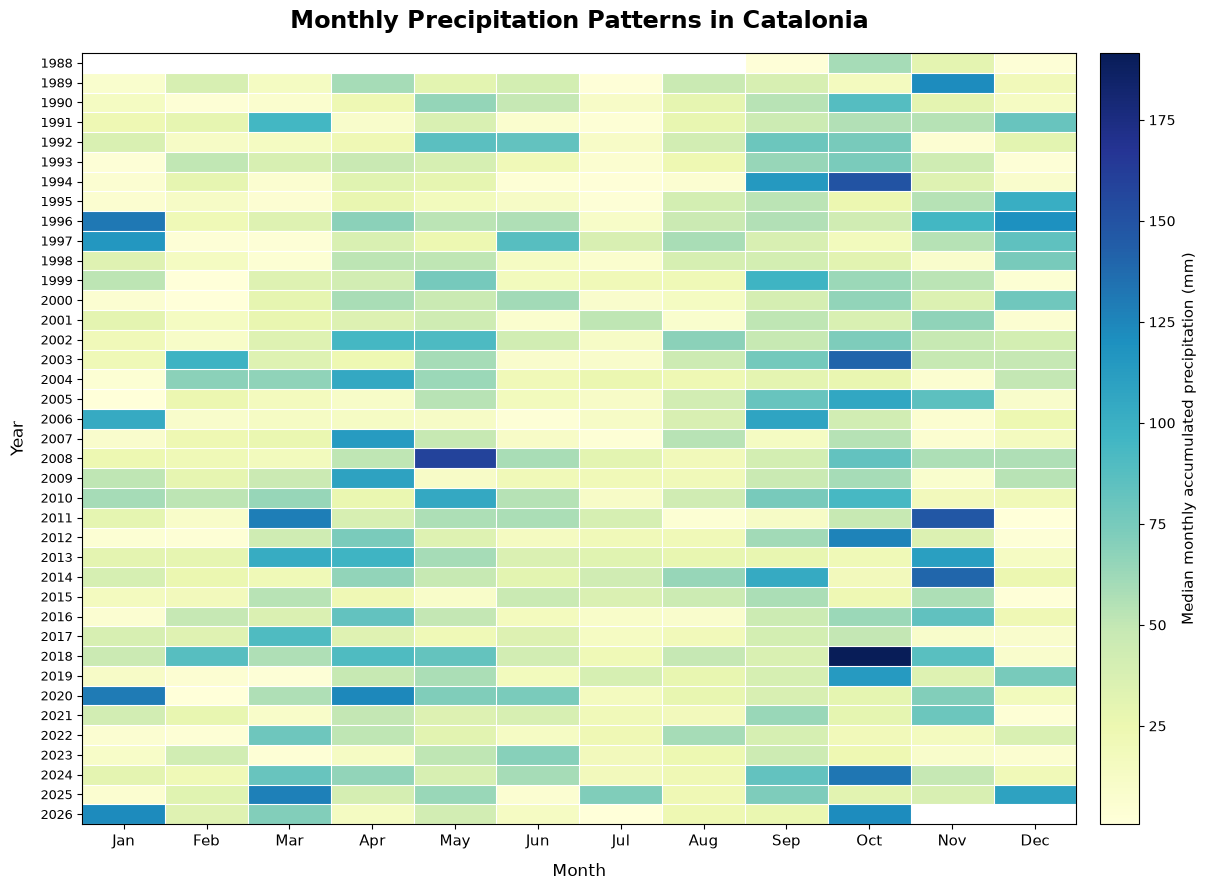

Years: 1988 - 2026
Available monthly observations: 458


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import calendar
import gc

file_path = r"C:\Users\nmayo\OneDrive\Escritorio\Máster - UB\Análisis de datos masivos\Datasets - Agua\Dades_meteorològiques_diàries_de_la_XEMA_20261116.csv"

# 1. Process the dataset in chunks
parts = []

for chunk in pd.read_csv(
    file_path,
    usecols=["CODI_ESTACIO", "DATA_LECTURA", "NOM_VARIABLE", "VALOR"],
    chunksize=200_000
):
    # Select daily accumulated precipitation
    chunk = chunk[
        chunk["NOM_VARIABLE"] == "Precipitació acumulada diària"
    ].copy()

    if chunk.empty:
        continue

    # Convert decimal comma into decimal point
    chunk["VALOR"] = pd.to_numeric(
        chunk["VALOR"].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

    chunk["DATA_LECTURA"] = pd.to_datetime(
        chunk["DATA_LECTURA"],
        format="%d/%m/%Y",
        errors="coerce"
    )

    chunk = chunk.dropna(subset=["VALOR", "DATA_LECTURA"])

    # Group by station and month
    chunk["MONTH"] = chunk["DATA_LECTURA"].dt.to_period("M")

    grouped = chunk.groupby(
        ["CODI_ESTACIO", "MONTH"]
    )["VALOR"].agg(["sum", "count"]).reset_index()

    parts.append(grouped)

    del chunk

# 2. Combine partial results
monthly = pd.concat(parts, ignore_index=True)

monthly = monthly.groupby(
    ["CODI_ESTACIO", "MONTH"]
).agg(
    precipitation=("sum", "sum"),
    days=("count", "sum")
).reset_index()

del parts
gc.collect()

# 3. Keep months with sufficient data coverage (at least 80%)
monthly["expected_days"] = monthly["MONTH"].apply(
    lambda x: x.days_in_month
)

monthly = monthly[
    monthly["days"] >= np.ceil(monthly["expected_days"] * 0.8)
].copy()

# 4. Calculate median monthly precipitation across stations
regional = monthly.groupby("MONTH")["precipitation"].median()

# 5. Create year-month matrix
heatmap_data = regional.reset_index()
heatmap_data["Year"] = heatmap_data["MONTH"].dt.year
heatmap_data["Month"] = heatmap_data["MONTH"].dt.month

matrix = heatmap_data.pivot(
    index="Year",
    columns="Month",
    values="precipitation"
)

matrix = matrix.reindex(columns=range(1, 13))

# 6. Plot the heatmap
fig, ax = plt.subplots(figsize=(13, 9))

im = ax.imshow(
    matrix.values,
    aspect="auto",
    cmap="YlGnBu",
    interpolation="nearest"
)

# Axis labels
ax.set_xticks(range(12))
ax.set_xticklabels(
    [calendar.month_abbr[m] for m in range(1, 13)],
    fontsize=11
)

ax.set_yticks(range(len(matrix.index)))
ax.set_yticklabels(matrix.index, fontsize=9)

ax.set_xlabel("Month", fontsize=12, labelpad=10)
ax.set_ylabel("Year", fontsize=12, labelpad=10)

ax.set_title(
    "Monthly Precipitation Patterns in Catalonia",
    fontsize=17,
    fontweight="bold",
    pad=18
)

# Colorbar
cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label(
    "Median monthly accumulated precipitation (mm)",
    fontsize=11
)

# Grid between cells
ax.set_xticks(np.arange(-0.5, 12, 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(matrix.index), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.8)
ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout()
plt.show()

print("Years:", matrix.index.min(), "-", matrix.index.max())
print("Available monthly observations:", matrix.notna().sum().sum())


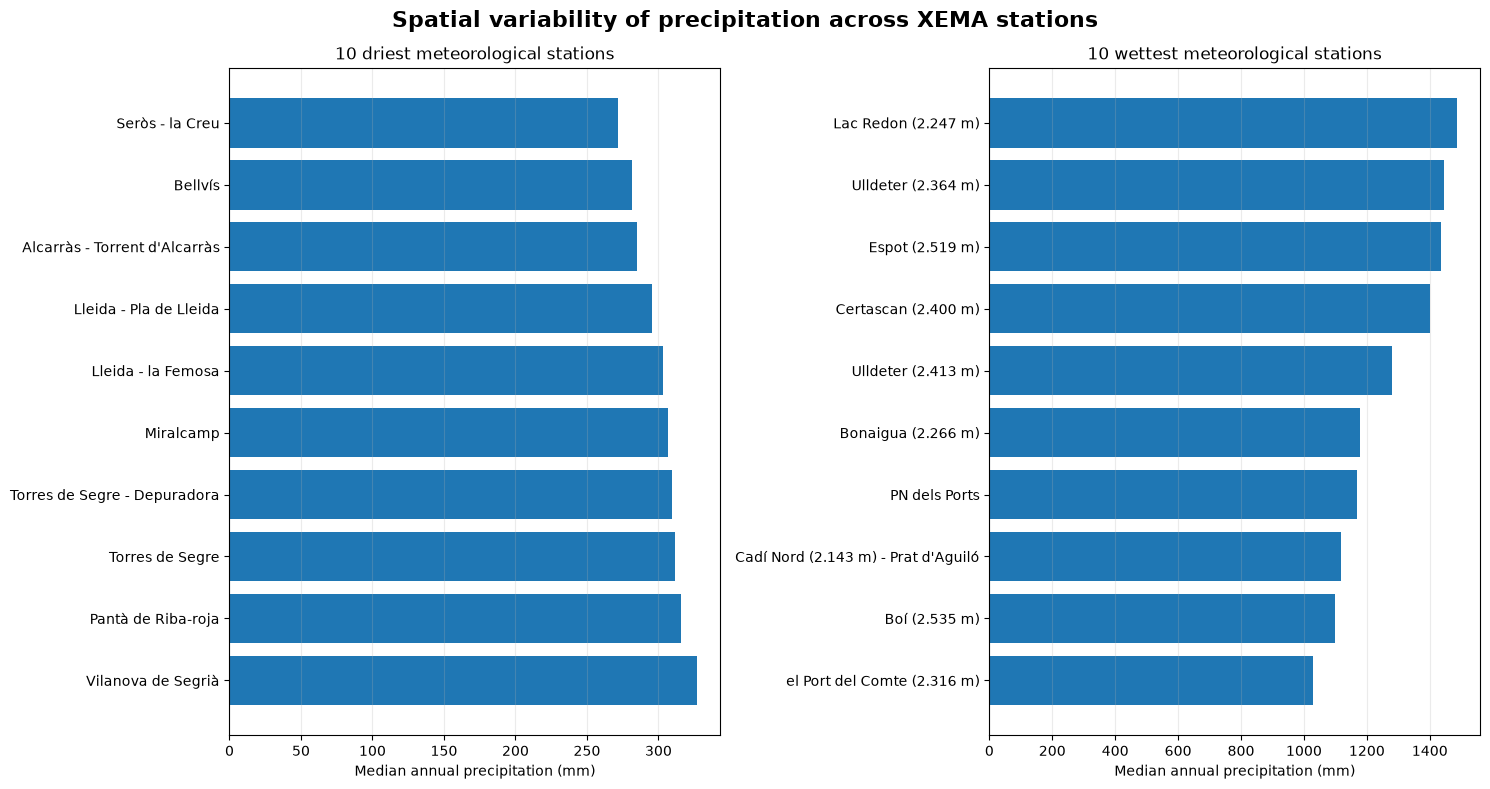

Stations with at least 5 valid years: 234


In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import calendar
import gc

file_path = r"C:\Users\nmayo\OneDrive\Escritorio\Máster - UB\Análisis de datos masivos\Datasets - Agua\Dades_meteorològiques_diàries_de_la_XEMA_20261116.csv"

parts = []

# Process data in chunks
for chunk in pd.read_csv(
    file_path,
    usecols=[
        "CODI_ESTACIO",
        "NOM_ESTACIO",
        "DATA_LECTURA",
        "NOM_VARIABLE",
        "VALOR"
    ],
    chunksize=200_000
):

    chunk = chunk[
        chunk["NOM_VARIABLE"] == "Precipitació acumulada diària"
    ].copy()

    if chunk.empty:
        continue

    chunk["VALOR"] = pd.to_numeric(
        chunk["VALOR"].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

    chunk["DATA_LECTURA"] = pd.to_datetime(
        chunk["DATA_LECTURA"],
        format="%d/%m/%Y",
        errors="coerce"
    )

    chunk = chunk.dropna(
        subset=["VALOR", "DATA_LECTURA"]
    )

    chunk["YEAR"] = chunk["DATA_LECTURA"].dt.year

    grouped = chunk.groupby(
        ["CODI_ESTACIO", "NOM_ESTACIO", "YEAR"]
    )["VALOR"].agg(["sum", "count"]).reset_index()

    parts.append(grouped)
    del chunk

# Combine partial results
annual = pd.concat(parts, ignore_index=True)

annual = annual.groupby(
    ["CODI_ESTACIO", "NOM_ESTACIO", "YEAR"]
).agg(
    precipitation=("sum", "sum"),
    days=("count", "sum")
).reset_index()

del parts
gc.collect()

# Require at least 80% daily coverage
annual["expected_days"] = annual["YEAR"].apply(
    lambda y: 366 if calendar.isleap(y) else 365
)

annual = annual[
    annual["days"] >= 0.8 * annual["expected_days"]
].copy()

# Calculate median annual precipitation per station
stations = annual.groupby(
    ["CODI_ESTACIO", "NOM_ESTACIO"]
).agg(
    median_annual_precipitation=("precipitation", "median"),
    valid_years=("YEAR", "nunique")
).reset_index()

# Retain stations with at least 5 valid years
stations = stations[stations["valid_years"] >= 5]

# Select 10 driest and 10 wettest stations
driest = stations.nsmallest(
    10, "median_annual_precipitation"
)

wettest = stations.nlargest(
    10, "median_annual_precipitation"
)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

axes[0].barh(
    driest["NOM_ESTACIO"],
    driest["median_annual_precipitation"]
)
axes[0].set_title("10 driest meteorological stations")
axes[0].set_xlabel("Median annual precipitation (mm)")
axes[0].invert_yaxis()
axes[0].grid(axis="x", alpha=0.25)

axes[1].barh(
    wettest["NOM_ESTACIO"],
    wettest["median_annual_precipitation"]
)
axes[1].set_title("10 wettest meteorological stations")
axes[1].set_xlabel("Median annual precipitation (mm)")
axes[1].invert_yaxis()
axes[1].grid(axis="x", alpha=0.25)

fig.suptitle(
    "Spatial variability of precipitation across XEMA stations",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("Stations with at least 5 valid years:", len(stations))
